# Assignment 2: Spatial Inequality to Access Green Spaces in Liverpool

In [1]:
# import necessary libraries
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import contextily as ctx
import osmnx as ox
import warnings
from matplotlib.lines import Line2D
import networkx as nx
import numpy as np
import mapclassify
import panel as pn
import seaborn as sns
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

## Introduction, Context, and Short literature review on the problem (~ 250 words)

Access to green space is increasingly recognised as both a public health issue and a planning issue. Parks, gardens and recreational lands can help reduce stress, encourage physical activity and improve mental wellbeing [1]. Proximity matters, people living within a five-minute walk of green space are 61% more likely to visit weekly than those living further away [2], making walking distance an important measure of real accessibility. However, this access is not equally distributed. Research has shown that deprived communities face poorer access to green infrastructure, which makes existing health and social inequalities even worse [3]. It also suggests that citywide averages can hide these differences and shifts the focus from how much green space a city must who can reach it [4].

In England, lower income neighbourhoods often have less access to green spaces than wealthier ones [5], and while factors such as quality and safety also affect how these spaces are used [6], walking distance remains the primary barrier to access these green spaces for many residents.

Liverpool is used as a case study for this research. As one of England's most deprived local authorities, it exhibits sharp intra-urban contrasts in wealth and environment. It was observed that Liverpool's deprived LSOAs have the lowest greenspace vegetation density among ten Northen English cities, yet are paradoxically closer to green spaces, spaces that are often environmentally compromised and of limited health benefit [8].

This project investigates whether more deprived areas in Liverpool have poorer walking access to green spaces across different LSOAs. It will use street work analysis and an interactive map to show where these inequalities are most noticeable.


### Introductory Static Map 1

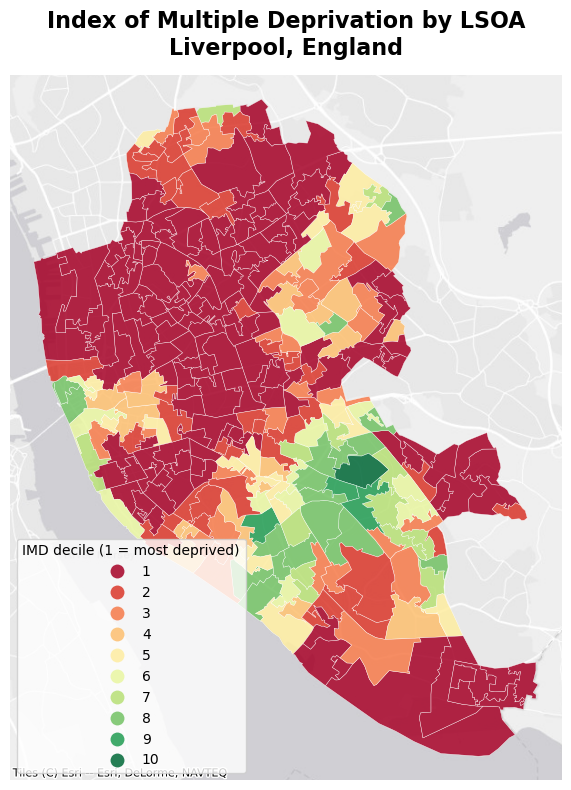

In [2]:
# load LSOA boundaries for England

imd_lsoa = gpd.read_file("data/IMD_2019.shp")

# filter to Liverpool only
liverpool = imd_lsoa[imd_lsoa["LADnm"] == "Liverpool"].copy()
liverpool = liverpool[["lsoa11cd", "lsoa11nm", "IMD_Rank", "IMD_Decile", "geometry"]]
liverpool.columns = ["LSOA11CD", "LSOA11NM", "IMD_Rank", "IMD_Decile", "geometry"]

# reproject to web mercator for basemap
liverpool_wm = liverpool.to_crs(epsg=3857)

# plot
fig, ax = plt.subplots(1, 1, figsize=(10, 8))
liverpool_wm.plot(
    column="IMD_Decile",
    cmap="RdYlGn",          # decile 1 (most deprived) = red
    categorical=True,
    legend=True,
    legend_kwds={
        "title": "IMD decile (1 = most deprived)",
        "loc": "lower left",
    },
    ax=ax,
    alpha=0.85,
    edgecolor="white",
    linewidth=0.3,
)
ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas)
ax.set_title(
    "Index of Multiple Deprivation by LSOA\nLiverpool, England",
    fontsize=16,
    fontweight="bold",
    pad=15,
)
ax.set_axis_off()

# Zoom to Liverpool bounds only
bounds = liverpool_wm.total_bounds
ax.set_xlim(bounds[0] - 1000, bounds[2] + 1000)
ax.set_ylim(bounds[1] - 1000, bounds[3] + 1000)
plt.tight_layout()
plt.show()

### Introductory Static Map 2

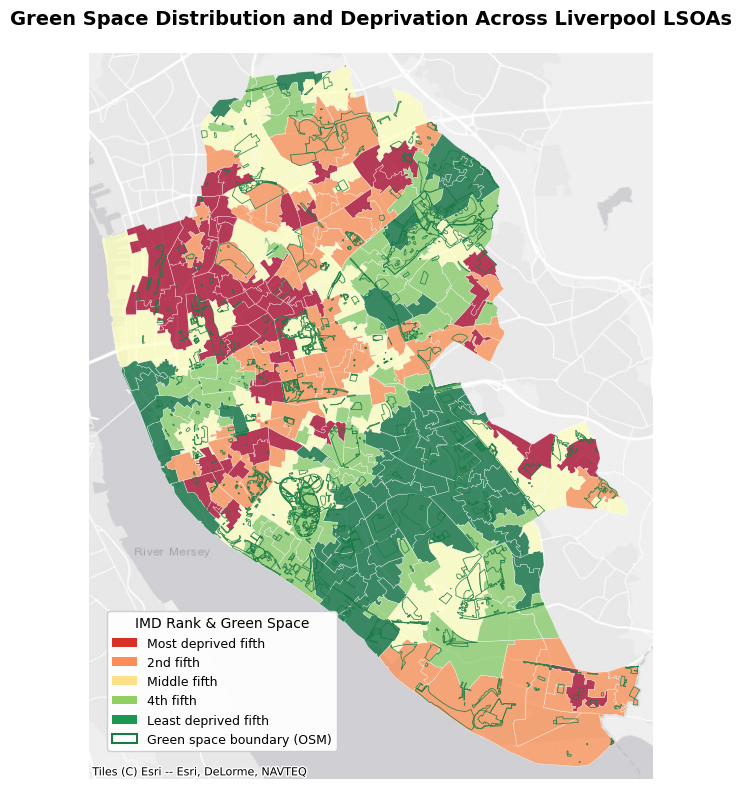

In [3]:
tags = {
    "leisure": ["park", "garden", "nature_reserve", "recreation_ground"],
    "landuse": ["recreation_ground", "village_green"],
    "natural": ["wood"]
}

green_spaces = ox.features_from_place("Liverpool, England", tags = tags)

# keep area geometrics only
green_spaces = green_spaces[green_spaces.geometry.geom_type.isin(["Polygon", "MultiPolygon"])].copy()

# remove private gardens (OSM tags many back gardens as leisure=garden)
private = green_spaces.get("access", pd.Series(index=green_spaces.index)).isin(["private", "no"]) | \
          green_spaces.get("garden:type", pd.Series(index=green_spaces.index)).isin(["residential", "private"])
green_spaces = green_spaces[~private].copy()

# reproject both layers
green_spaces_wm = green_spaces.to_crs(epsg = 3857)

# Clip to Liverpool LSOA envelope
liverpool_union = liverpool_wm.unary_union
green_spaces_wm = gpd.clip(green_spaces_wm, liverpool_union)

# 2) Plot
fig, ax = plt.subplots(1, 1, figsize=(10, 8))

# Neutral LSOA background 
liverpool_wm.plot(
    column="IMD_Rank", cmap="RdYlGn", scheme="quantiles", k=5,   # low rank (most deprived) = red
    legend=False, ax=ax, alpha=0.75, edgecolor="white", linewidth=0.3,
)

# Green spaces layer
green_spaces_wm.boundary.plot(
    ax=ax,
    color="#1a7a45",
    linewidth=0.6,
    alpha=0.85
)

# Basemap
ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas)

# Fixed extent to Liverpool
bounds = liverpool_wm.total_bounds
ax.set_xlim(bounds[0] - 500, bounds[2] + 500)
ax.set_ylim(bounds[1] - 500, bounds[3] + 500)

# One combined manual legend
legend_elements = [
    mpatches.Patch(facecolor='#d73027', label='Most deprived fifth'),
    mpatches.Patch(facecolor='#fc8d59', label='2nd fifth'),
    mpatches.Patch(facecolor='#fee08b', label='Middle fifth'),
    mpatches.Patch(facecolor='#91cf60', label='4th fifth'),
    mpatches.Patch(facecolor='#1a9850', label='Least deprived fifth'),
    mpatches.Patch(facecolor='none', edgecolor='#1a7a45',
                   linewidth=1.5, label='Green space boundary (OSM)'),
]

ax.legend(
    handles=legend_elements,
    title="IMD Rank & Green Space",
    title_fontsize=10,
    fontsize=9,
    loc="lower left",
    bbox_to_anchor=(0.02,0.03),
    framealpha=0.95,
)

ax.set_title("Green Space Distribution and Deprivation Across Liverpool LSOAs", fontsize=14, fontweight="bold", pad=10)
ax.set_axis_off()
plt.tight_layout()
plt.show()

### Introductory Static Map 3

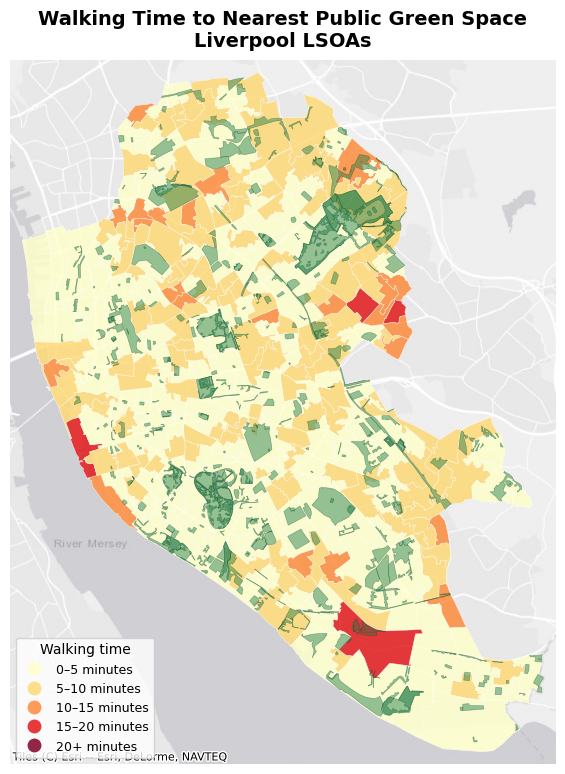

In [4]:
# Downloading the  Liverpool walking network
G = ox.graph_from_place(
    "Liverpool, England",
    network_type="walk",
    simplify=True
)

# Prepare LSOA representative points
liverpool_27700 = liverpool.to_crs(epsg=27700).copy()
liverpool_27700["rep_point"] = liverpool_27700.geometry.representative_point()

lsoa_points = gpd.GeoDataFrame(
    liverpool_27700[["LSOA11CD", "LSOA11NM", "IMD_Rank", "IMD_Decile"]],
    geometry=liverpool_27700["rep_point"],
    crs=27700
).to_crs(epsg=4326)

# Prepare green space representative points
green_spaces_27700 = green_spaces_wm.to_crs(epsg=27700).copy()

# removing very tiny green spaces
green_spaces_27700["area_m2"] = green_spaces_27700.geometry.area
green_spaces_27700 = green_spaces_27700[green_spaces_27700["area_m2"] > 1000].copy()

green_spaces_27700["rep_point"] = green_spaces_27700.geometry.representative_point()

green_points = gpd.GeoDataFrame(
    green_spaces_27700[["area_m2"]],
    geometry=green_spaces_27700["rep_point"],
    crs=27700
).to_crs(epsg=4326)

# Snap LSOA points and green spaces to nearest walking network nodes
lsoa_points["nearest_node"] = ox.distance.nearest_nodes(
    G,
    X=lsoa_points.geometry.x,
    Y=lsoa_points.geometry.y
)

green_points["nearest_node"] = ox.distance.nearest_nodes(
    G,
    X=green_points.geometry.x,
    Y=green_points.geometry.y
)

green_nodes = list(green_points["nearest_node"].dropna().unique())

# Calculate shortest walking distance from all green spaces
lengths = nx.multi_source_dijkstra_path_length(
    G,
    sources=green_nodes,
    weight="length"
)

# Attach distance to each LSOA
lsoa_points["distance_to_green_m"] = lsoa_points["nearest_node"].map(lengths)

# Convert distance to walking time
lsoa_points["walking_time_min"] = lsoa_points["distance_to_green_m"] / 80 # Approximate walking speed: 80 metres per minute

# Join the results back to LSOA polygons
liverpool_access = liverpool_27700.merge(
    lsoa_points[["LSOA11CD", "distance_to_green_m", "walking_time_min"]],
    on="LSOA11CD",
    how="left"
)

# Convert to Web Mercator for basemap
liverpool_access_wm = liverpool_access.to_crs(epsg=3857)
green_spaces_access_wm = green_spaces_27700.to_crs(epsg=3857)

# Create walking time categories
bins = [0, 5, 10, 15, 20, np.inf]
labels = [
    "0–5 minutes",
    "5–10 minutes",
    "10–15 minutes",
    "15–20 minutes",
    "20+ minutes"
]

liverpool_access_wm["access_category"] = pd.cut(
    liverpool_access_wm["walking_time_min"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Plot static map
fig, ax = plt.subplots(1, 1, figsize=(10, 8))

liverpool_access_wm.plot(
    column="access_category",
    cmap="YlOrRd",          # sequential: darker = longer walk (colour-blind safe)
    legend=True,
    legend_kwds={"title": "Walking time", "loc": "lower left", "fontsize": 9, "title_fontsize": 10},
    ax=ax,
    edgecolor="white",
    linewidth=0.3,
    alpha=0.85,
    missing_kwds={
        "color": "lightgrey",
        "label": "No data"
    }
)


green_spaces_access_wm.plot(
    ax=ax,
    color="#1a7a45",
    alpha=0.45,
    edgecolor="#0b4f2a",
    linewidth=0.4
)


ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas)


bounds = liverpool_wm.total_bounds
ax.set_xlim(bounds[0] - 500, bounds[2] + 500)
ax.set_ylim(bounds[1] - 500, bounds[3] + 500)

ax.set_title(
    "Walking Time to Nearest Public Green Space\nLiverpool LSOAs",
    fontsize=14,
    fontweight="bold",
    pad=10
)

ax.set_axis_off()
plt.tight_layout()
plt.show()

### Static Map 4: Bivariate Map

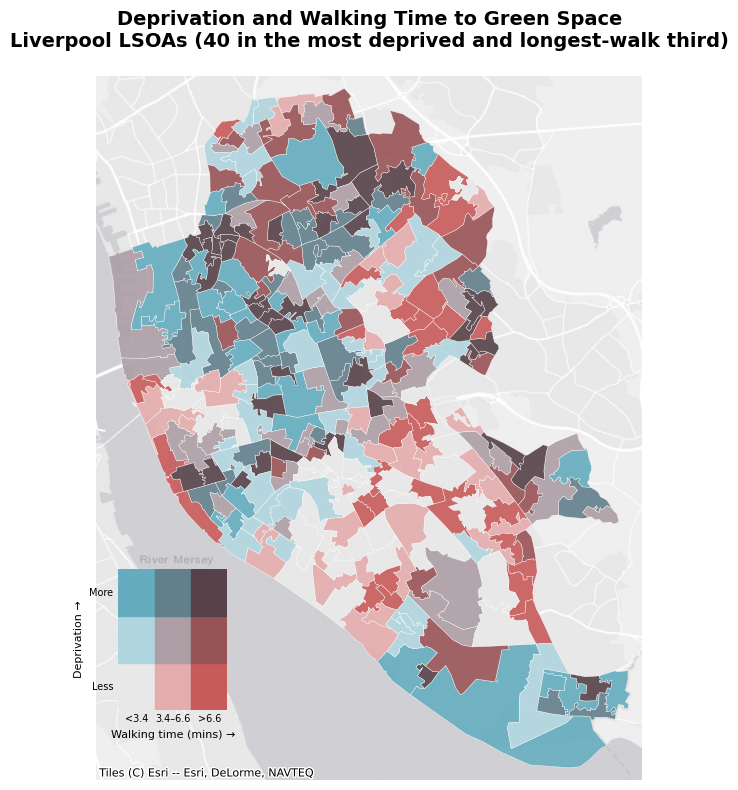

In [5]:
# Bivariate map: deprivation x walking time
# Both variables are split into thirds (terciles) within Liverpool, giving a 3 x 3 colour grid

# 3 x 3 colour scheme: rows = deprivation (0 = least, 2 = most), columns = walking time (0 = shortest, 2 = longest)
bivariate_colours = {
    (0, 0): "#e8e8e8", (0, 1): "#e4acac", (0, 2): "#c85a5a",
    (1, 0): "#b0d5df", (1, 1): "#ad9ea5", (1, 2): "#985356",
    (2, 0): "#64acbe", (2, 1): "#627f8c", (2, 2): "#574249",
}

bivar = liverpool_access_wm.dropna(subset=["walking_time_min"]).copy()

# IMD rank 1 = most deprived, so reverse the terciles so that 2 = most deprived third
bivar["dep_class"] = 2 - pd.qcut(bivar["IMD_Rank"], 3, labels=False)
bivar["walk_class"] = pd.qcut(bivar["walking_time_min"].rank(method="first"), 3, labels=False)
bivar["bivar_colour"] = [bivariate_colours[(d, w)] for d, w in zip(bivar["dep_class"], bivar["walk_class"])]

# walking-time cut-offs for the legend labels
walk_cuts = bivar["walking_time_min"].quantile([1/3, 2/3]).round(1).tolist()

# Plot
fig, ax = plt.subplots(1, 1, figsize=(10, 8))

bivar.plot(
    color=bivar["bivar_colour"],
    ax=ax,
    edgecolor="white",
    linewidth=0.3,
    alpha=0.9
)

ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas)

bounds = liverpool_wm.total_bounds
ax.set_xlim(bounds[0] - 500, bounds[2] + 500)
ax.set_ylim(bounds[1] - 500, bounds[3] + 500)

# 3 x 3 legend drawn as a small inset grid
legend_ax = ax.inset_axes([0.04, 0.1, 0.2, 0.2])
for (d, w), colour in bivariate_colours.items():
    legend_ax.add_patch(mpatches.Rectangle((w, d), 1, 1, color=colour))
legend_ax.set_xlim(0, 3)
legend_ax.set_ylim(0, 3)
legend_ax.set_xticks([0.5, 1.5, 2.5])
legend_ax.set_xticklabels([f"<{walk_cuts[0]}", f"{walk_cuts[0]}–{walk_cuts[1]}", f">{walk_cuts[1]}"], fontsize=7)
legend_ax.set_yticks([0.5, 2.5])
legend_ax.set_yticklabels(["Less", "More"], fontsize=7)
legend_ax.set_xlabel("Walking time (mins) →", fontsize=8)
legend_ax.set_ylabel("Deprivation →", fontsize=8)
legend_ax.tick_params(length=0)
for spine in legend_ax.spines.values():
    spine.set_visible(False)

# count LSOAs where high deprivation and long walks overlap
n_worst = ((bivar["dep_class"] == 2) & (bivar["walk_class"] == 2)).sum()

ax.set_title(
    f"Deprivation and Walking Time to Green Space\nLiverpool LSOAs ({n_worst} in the most deprived and longest-walk third)",
    fontsize=14,
    fontweight="bold",
    pad=10
)
ax.set_axis_off()
plt.tight_layout()
plt.show()

## Data Sources Presentation (~ 250 words)

Three primary data sources were chosen for their ability to capture a distinct dimension of the research problem at the neighbourhood scale.
The first data is the ONS LSOA boundary file (December 2021, England) which provides the spatial units underpinning the analysis. Lower Super Output Areas are small, standardised neighbourhoods of approximately 1500 residents, designed to be consistent in population size and hence comparable across the city, Liverpool was used as the city of study and it contained 298 urban LSOAs, providing enough spatial resolution to detect variations across the city.

The next data comes from the Index of Multiple Deprivation 2019 published by MHCLG, IMD scores are calculated at the LSOA level and combine seven domains: income, employment, education, health, crime, housing and living environment into one single aggregated score. This makes it the most appropriate measure for capturing socioeconomic disadvantage at neighbourhood level in England and it is the standard variable used in comparable UK studies [7].

For the final data, which is the green space data, and it was pulled from the OpenStreetMap (OSM) using the osmnx Python library. Certain features tagged as parks, gardens, recreational grounds, meadows, allotments and village greens were extracted and filtered to polygon geometrics only, which gave 3689 green space features across Liverpool. OSM is not perfectly complete, but it is the most comprehensive open dataset available for urban green infrastructure at this scale [4][7].


### Geovisualisation and Analysis Rationale (~ 200 words)

The final geo-visualisation medium is an interactive Panel dashboard that was designed to communicate spatial inequality in access to green spaces in Liverpool. The main story is not where parks are located but whether residents in more deprived neighbourhoods must travel further, in real walking terms to reach them. The dashboard was created to tell this story clearly, it combines three linked views: a choropleth map of deprivation, a map of network-based walking time to the nearest green space and finally an analytical summary panel with charts and key indicators. Users can switch layers. filter neighbourhoods by deprivation group and adjust the walking time thresholds to explore how inequality changes across the city.

The main analytical component goes beyond Geographic/ Street Network Analysis, instead of using straight line distances, the shortest path walking distance from each LSOA representative point to the nearest green space access point was calculated using the OpenStreetMap pedestrian network. The distances were then converted into walking time and compared against IMD deciles to identify inequity hotspots. The dashboard is designed to support an evidence-based narrative, city wide averages can hide unequal local outcomes and planning decisions should make sure to prioritise places where social disadvantages overlap with low green space accessibility.



In [6]:
import panel as pn
import folium
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from branca.colormap import linear, LinearColormap

pn.extension()

# data preparation
dash_lsoa = liverpool_access.to_crs(epsg=4326).copy()
dash_green = green_spaces_27700.to_crs(epsg=4326).copy()

dash_lsoa = dash_lsoa.drop(columns=["rep_point", "origin_point"], errors="ignore")
dash_green = dash_green.drop(columns=["rep_point", "origin_point"], errors="ignore")

dash_lsoa["IMD_Rank"] = pd.to_numeric(dash_lsoa["IMD_Rank"], errors="coerce")
dash_lsoa["IMD_Decile"] = pd.to_numeric(dash_lsoa["IMD_Decile"], errors="coerce")
dash_lsoa["distance_to_green_m"] = pd.to_numeric(dash_lsoa["distance_to_green_m"], errors="coerce")
dash_lsoa["walking_time_min"] = pd.to_numeric(dash_lsoa["walking_time_min"], errors="coerce")

# simplify outlines and round coordinates (to about 1 m) to keep the exported dashboard small
import shapely
dash_green["geometry"] = shapely.set_precision(dash_green.geometry.simplify(0.00005, preserve_topology=True).values, 1e-5)
dash_green = dash_green[["geometry"]]
dash_lsoa["geometry"] = shapely.set_precision(dash_lsoa.geometry.simplify(0.00002, preserve_topology=True).values, 1e-5)
dash_lsoa["distance_to_green_m"] = dash_lsoa["distance_to_green_m"].round(0)
dash_lsoa["walking_time_min"] = dash_lsoa["walking_time_min"].round(1)
green_json = dash_green.to_json()

# bring in the bivariate colours from Static Map 4
dash_lsoa = dash_lsoa.merge(bivar[["LSOA11CD", "bivar_colour"]], on="LSOA11CD", how="left")

q80 = dash_lsoa["walking_time_min"].quantile(0.8)
dash_lsoa["hotspot"] = (dash_lsoa["IMD_Decile"] <= 2) & (dash_lsoa["walking_time_min"] >= q80)

center_lat = float(dash_lsoa.geometry.centroid.y.mean())
center_lon = float(dash_lsoa.geometry.centroid.x.mean())

# fixed sizes used across the layout so panels line up
MAP_W, SIDE_W = 860, 480
kpi_style = dict(font_size="26pt", title_size="11pt", width=150, margin=(5, 5))

# widgets for interactive map
layer_selector = pn.widgets.RadioButtonGroup(
    name="Map Layer",
    options=["Walking Time (mins)", "IMD Decile", "Bivariate", "Hotspots"],
    value="Walking Time (mins)",
    button_type="success",
    width=420
)

deprivation_filter = pn.widgets.Select(
    name="Filter by Deprivation",
    options={
        "All LSOAs": "all",
        "Most deprived (deciles 1-2)": "most",
        "Mid range (deciles 3-7)": "mid",
        "Least deprived (deciles 8-10)": "least",
    },
    value="all",
    width=240
)

# step of 5 minutes keeps the number of pre-computed states (and the exported file size) down
max_time_end = int(np.ceil(max(20, dash_lsoa["walking_time_min"].dropna().max()) / 5) * 5)
max_time_slider = pn.widgets.IntSlider(
    name="Max walking time shown (mins)",
    start=5,
    end=max_time_end,
    value=max_time_end,
    step=5,
    width=240
)


def filter_data(deprivation, max_time):
    d = dash_lsoa.copy()
    if deprivation == "most":
        d = d[d["IMD_Decile"] <= 2]
    elif deprivation == "mid":
        d = d[(d["IMD_Decile"] >= 3) & (d["IMD_Decile"] <= 7)]
    elif deprivation == "least":
        d = d[d["IMD_Decile"] >= 8]
    d = d[d["walking_time_min"] <= max_time]
    d = d.dropna(subset=["IMD_Decile", "walking_time_min", "geometry"]).copy()
    return d

# map
def create_map(layer, deprivation, max_time):
    data = filter_data(deprivation, max_time)

    m = folium.Map(location=[center_lat, center_lon], zoom_start=11, tiles=None)
    folium.TileLayer(tiles="https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}", attr="Tiles &copy; Esri", control=False).add_to(m)   # basemap stays on, not listed in the layer control

    if data.empty:
        folium.Marker([center_lat, center_lon], tooltip="No LSOAs match current filters").add_to(m)
        return m

    keep_cols = ["LSOA11CD", "LSOA11NM", "IMD_Rank", "IMD_Decile",
                 "distance_to_green_m", "walking_time_min", "hotspot", "bivar_colour", "geometry"]
    data = data[[c for c in keep_cols if c in data.columns]].copy()
    data_json = data.to_json()

    if layer == "Bivariate":
        # same 3 x 3 colours as Static Map 4
        lsoa_layer = folium.GeoJson(
            data_json,
            name="Bivariate: deprivation x walking time",
            style_function=lambda f: {
                "fillColor": f["properties"]["bivar_colour"] or "#d9d9d9",
                "fillOpacity": 0.85,
                "color": "white",
                "weight": 0.5
            }
        ).add_to(m)
        cells = "".join(
            f'<div style="background:{bivariate_colours[(d, w)]};width:18px;height:18px"></div>'
            for d in (2, 1, 0) for w in (0, 1, 2)
        )
        m.get_root().html.add_child(folium.Element(f"""
            <div style="position:fixed;bottom:24px;left:24px;z-index:1000;background:white;padding:8px 10px;
                        border-radius:6px;box-shadow:0 1px 4px rgba(0,0,0,.3);font:11px Arial,sans-serif">
              <b>Bivariate</b>
              <div style="display:flex;align-items:center;margin-top:4px">
                <div style="writing-mode:vertical-rl;transform:rotate(180deg);margin-right:4px">Deprivation &rarr;</div>
                <div style="display:grid;grid-template-columns:repeat(3,18px);gap:1px">{cells}</div>
              </div>
              <div style="margin-left:16px">Walking time &rarr;</div>
            </div>"""))
    else:
        if layer == "IMD Decile":
            map_col = "IMD_Decile"
            fill_color = "RdYlGn"          # decile 1 (most deprived) = red, matches Static Map 1
            legend_name = "IMD decile (1 = most deprived)"
        else:
            map_col = "walking_time_min"
            fill_color = "YlOrRd"          # darker = longer walk, matches Static Map 3
            legend_name = "Walking time to nearest green space (mins)"

        choropleth = folium.Choropleth(
            geo_data=data_json,
            data=data,
            columns=["LSOA11CD", map_col],
            key_on="feature.properties.LSOA11CD",
            fill_color=fill_color,
            fill_opacity=0.75,
            line_opacity=0.35,
            line_color="white",
            legend_name=legend_name,
            nan_fill_color="lightgrey",
            name="LSOA choropleth"
        ).add_to(m)
        lsoa_layer = choropleth.geojson

    # tooltips go on the coloured layer itself (no second copy of the polygons)
    lsoa_layer.add_child(folium.GeoJsonTooltip(
        fields=["LSOA11NM", "IMD_Rank", "IMD_Decile", "distance_to_green_m", "walking_time_min"],
        aliases=["Neighbourhood:", "IMD Rank:", "IMD Decile:", "Distance (m):", "Walk time (mins):"],
        localize=True
    ))

    if layer == "Hotspots":
        hotspots = data[data["hotspot"] == True]
        if not hotspots.empty:
            folium.GeoJson(
                hotspots.to_json(),
                name="Hotspots",
                style_function=lambda x: {"fillOpacity": 0, "color": "#b10026", "weight": 2.2},
                tooltip=folium.Tooltip("Hotspot: deciles 1-2 + longest walking times")
            ).add_to(m)

    # green spaces can be switched on and off in the map's layer control
    folium.GeoJson(
        green_json,
        name="Green spaces",
        style_function=lambda x: {
            "fillColor": "#2d9e5f",
            "color": "#1a7a45",
            "weight": 0.6,
            "fillOpacity": 0.18
        }
    ).add_to(m)

    minx, miny, maxx, maxy = data.total_bounds
    m.fit_bounds([[miny, minx], [maxy, maxx]])
    folium.LayerControl(collapsed=False).add_to(m)
    return m

@pn.depends(layer_selector.param.value, deprivation_filter.param.value, max_time_slider.param.value)
def update_map(layer, deprivation, max_time):
    return pn.pane.HTML(create_map(layer, deprivation, max_time)._repr_html_(), width=MAP_W, height=560)

# kpis
@pn.depends(deprivation_filter.param.value, max_time_slider.param.value)
def kpi_panel(deprivation, max_time):
    d = filter_data(deprivation, max_time)
    if d.empty:
        return pn.pane.Markdown("No data for current filters.")
    return pn.Row(
        pn.indicators.Number(name="Mean walk time", value=float(d["walking_time_min"].mean()), format="{value:.1f} min", **kpi_style),
        pn.indicators.Number(name="Median walk time", value=float(d["walking_time_min"].median()), format="{value:.1f} min", **kpi_style),
        pn.indicators.Number(name="Hotspot share", value=float((d["hotspot"] == True).mean() * 100), format="{value:.1f}%", **kpi_style),
        width=SIDE_W
    )

# charts
def make_bar(deprivation, max_time):
    d = filter_data(deprivation, max_time)
    fig, ax = plt.subplots(figsize=(4.7, 3.0))
    if d.empty:
        ax.text(0.5, 0.5, "No data for current filters", ha="center", va="center"); ax.axis("off")
    else:
        s = d.groupby("IMD_Decile", as_index=False)["walking_time_min"].mean()
        sns.barplot(data=s, x="IMD_Decile", y="walking_time_min", color="#2d9e5f", ax=ax)
        ax.set_title("Mean Walking Time by IMD Decile")
        ax.set_xlabel("IMD Decile (1=most deprived)"); ax.set_ylabel("Minutes")
    pane = pn.pane.Matplotlib(fig, tight=True, width=SIDE_W, height=300); plt.close(fig); return pane

def make_box(deprivation, max_time):
    d = filter_data(deprivation, max_time)
    fig, ax = plt.subplots(figsize=(4.7, 3.0))
    if d.empty:
        ax.text(0.5, 0.5, "No data for current filters", ha="center", va="center"); ax.axis("off")
    else:
        sns.boxplot(data=d, x="IMD_Decile", y="walking_time_min", color="#91cf60", ax=ax)
        ax.set_title("Distribution by IMD Decile")
        ax.set_xlabel("IMD Decile (1=most deprived)"); ax.set_ylabel("Minutes")
    pane = pn.pane.Matplotlib(fig, tight=True, width=SIDE_W, height=300); plt.close(fig); return pane

def make_hist(deprivation, max_time):
    d = filter_data(deprivation, max_time)
    fig, ax = plt.subplots(figsize=(4.7, 3.0))
    if d.empty:
        ax.text(0.5, 0.5, "No data for current filters", ha="center", va="center"); ax.axis("off")
    else:
        sns.histplot(d["walking_time_min"], bins=20, color="#fc8d59", ax=ax)
        ax.set_title("Walking Time Distribution")
        ax.set_xlabel("Minutes"); ax.set_ylabel("LSOA count")
    pane = pn.pane.Matplotlib(fig, tight=True, width=SIDE_W, height=300); plt.close(fig); return pane

bar_view = pn.bind(make_bar, deprivation_filter, max_time_slider)
box_view = pn.bind(make_box, deprivation_filter, max_time_slider)
hist_view = pn.bind(make_hist, deprivation_filter, max_time_slider)

chart_tabs = pn.Tabs(
    ("Mean by Decile", bar_view),
    ("Distribution by Decile", box_view),
    ("Histogram", hist_view),
    dynamic=False,
    width=SIDE_W
)

# layout: one fixed grid so the map and the summary column line up at the top and bottom
left_panel = pn.Column(pn.pane.Markdown("### Interactive Map", margin=(0, 10), disable_anchors=True), update_map, width=MAP_W + 20)
right_panel = pn.Column(pn.pane.Markdown("### Analytical Summary", margin=(0, 10), disable_anchors=True), kpi_panel, chart_tabs, width=SIDE_W + 20)

controls = pn.Row(layer_selector, deprivation_filter, max_time_slider,
                  width=MAP_W + SIDE_W + 60, align="center")

final_dashboard = pn.Column(
    pn.pane.Markdown("## Liverpool Green Space Access Dashboard", margin=(0, 10), disable_anchors=True),
    pn.pane.Markdown("*Map and charts update together based on deprivation and walk-time filters.*", margin=(0, 10)),
    controls,
    pn.Row(left_panel, pn.Spacer(width=20), right_panel),
    width=MAP_W + SIDE_W + 80
)


### Interactivity and design choices (~ 200 words)

The dashboard's interactivity is designed to help users move from broad spatial patterns to neighbourhood level detail without losing context. At the cartographic level, I used a web map interface that supports zooming and panning, thereby allowing users to inspect city-wide inequality first and then focus on specific clusters of LSOAs. A light basemap is used to preserve the orientation while keeping thematic layers visually dominant. The choropleth polygons use semi-transparent fills and thin white boundaries to maintain legibility across zoom levels, while green space overlays are styled with lower opacity, so they remain visible but do not overpower the deprivation and accessibility variables.

The interface also includes a layer selector (walking time, IMD rank, hotspots) so users can compare the different dimensions of inequality through the same spatial frame. A deprivation filter and maximum walking time slider was also included to allow targeted exploration of vulnerable groups and make threshold-based interpretations which helps to support policy-oriented questions such as where long walking times persist among deprived areas. Tooltips provide local attribute detail on hover, reducing clutter compared with permanent labels.
An analytical summary card and linked charts were added, and they can update with the same filters of the final map, this creates coordinated multiple views where map interpretation is immediately supported by statistical context.



### For panel-Dashboard students only, follow procedure below

In [ ]:
from bokeh.resources import INLINE
from IPython.display import HTML
import panel as pn

# Final Dashboard (one) code (replace with code and comments)
pn.extension() # do not remove
dashboard = final_dashboard # your dashboard code

# Save and reload - Necessary to upload on Canvas a self-contained html file
dashboard.save('dashboard.html', embed=True, resources=INLINE)

with open('dashboard.html', 'r') as file:
    html_dashboard = file.read()

# Display the HTML content in the notebook
HTML(html_dashboard)

### Conclusion (~ 100 words)

This project examined whether deprivation is associated with poorer walkable access to green spaces across Liverpool's LSOAs. To tackle this problem, a combination of IMD data, LSOA boundaries and OpenStreetMap green space polygons were employed. Using network based shortest path rather than straight line distances, I estimated the walking time/distance from each neighbourhood to its nearest green space. Results were communicated via three static maps and a panel dashboard with filters, tooltips and linked summary charts. The geo-visualisation shows that accessibility is spatially uneven with clear local hotspots where social disadvantage and longer walking times overlap. This suggests that green space provision in Liverpool does not yet meet the needs of its most deprived communities equally.

Total word count prose text: 1040

### References

[1]J. R. Wolch, J. Byrne, and J. P. Newell, “Urban green space, public health, and environmental justice: The challenge of making cities ‘just green enough,’” Landscape and Urban Planning, vol. 125, no. 125, pp. 234–244, May 2014, doi: https://doi.org/10.1016/j.landurbplan.2014.01.017.

[2]C. Wendelboe-Nelson, Y. Wang, S. Bell, C. W. McDougall, and C. Ward Thompson, “Your Favourite Park Is Not My Favourite Park: A Participatory Geographic Information System Approach to Improving Urban Green and Blue Spaces—A Case Study in Edinburgh, Scotland,” Land, vol. 13, no. 3, p. 395, Mar. 2024, doi: https://doi.org/10.3390/land13030395.

[3]A. Rigolon, “A complex landscape of inequity in access to urban parks: A literature review,” Landscape and Urban Planning, vol. 153, no. 0169-2046, pp. 160–169, Sep. 2016, doi: https://doi.org/10.1016/j.landurbplan.2016.05.017.

[4]J. Martinez, J. Argota Sánchez-Vaquerizo, and S. Mahajan, “Not your mean green: beyond averages in mapping socio-spatial inequities in urban greenery for smart cities,” EPJ Data Science, vol. 15, no. 1, Feb. 2026, doi: https://doi.org/10.1140/epjds/s13688-026-00627-4.

[5]O. Barbosa et al., “Who benefits from access to green space? A case study from Sheffield, UK,” Landscape and Urban Planning, vol. 83, no. 2–3, pp. 187–195, Nov. 2007.

[6]V. Jennings, L. Larson, and J. Yun, “Advancing Sustainability through Urban Green Space: Cultural Ecosystem Services, Equity, and Social Determinants of Health,” International Journal of Environmental Research and Public Health, vol. 13, no. 2, p. 196, Feb. 2016, doi: https://doi.org/10.3390/ijerph13020196.

[7]M. V. Martin, L. M. Holland, and P. Brindley, “Greenspace and air pollution disparities in urban Northern England,” Journal of Environmental Management, vol. 399, no. 0301-4797, p. 128493, Feb. 2026, doi: https://doi.org/10.1016/j.jenvman.2025.128493.